# QPDK filled qubit test chip — the qubit test chip with QPDK's vortex-trap fill (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/filled_test_chip.py`
(`filled_qubit_test_chip`), <https://github.com/gdsfactory/quantum-rf-pdk> — **MIT licence** (gdsfactory 2024;
depth-1 clone read 2026-11-03, never executed). Spec: `docs/designs/qpdk/filled_qubit_test_chip.md`. QPDK says
the sample "roughly corresponds" to Tuokkola et al., Nat. Commun. 2025 (near-millisecond transmons). QPDK loads
the [qubit test chip](qubit_test_chip.ipynb) YAML **unchanged**, fills the ground plane with vortex-trapping
holes — `fill_magnetic_vortices(rectangle_size=(15, 15), gap=70, stagger=2)`, which fills the chip's bounding box
with 15 × 15 µm etched squares on an 85 µm pitch, each row staggered by 2 µm, keeping 80 µm from every etched,
drawn or waveguide shape (`_EXCLUDE_LAYERS_DEFAULT_M1` in `qpdk/utils.py`) — adds a 100 µm etched `chip_edge`
around the layout and converts the result to a negative mask.

This notebook **rebuilds** it on the Quantcore PDK (not a replica); we distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| layout | the qubit test chip, unchanged | `qubit_test_chip.json` loaded unchanged: the 7.5 mm die, pads 100 µm (`frame.pad_edge`) from the edge, the whole layout centred (pads included), trilayer SQUIDs (see that notebook) |
| chip edge | 100 µm etched `chip_edge` around the layout | the Quantcore die frame (dicing L's, alignment grids, boundary 100/0), device ID "QPDK-FQTC" |
| cheese | **QPDK's vortex fill**: 15 µm squares, 85 µm pitch, 80 µm clear of every shape | **the original wins:** the same fill as the chip's `cheese` rule (`QP.vortex_fill(d)` → a rule dict): the build draws it instead of the PDK band, and `export_fab` / `qcc mask` keep it |
| substrate, junctions | Al on Si, evaporated Al SQUIDs | sapphire 650 µm, εr 10.25; Quantcore trilayer SQUIDs |

**The fill, as the PDK can express it:** a `CheeseRule` of 15 µm squares with 70 µm gaps over the whole design
area, at least 70 µm from the 3/0 keep-outs (= 80 µm from every route's CPW gap, since 3/0 already adds 10 µm
round each CPW; around components 3/0 adds 24 µm, so the holes there stay ≥ 94 µm from the etch bbox). Not
reproduced: the 2 µm row stagger (a `CheeseRule` is a square grid), and QPDK fills only the layout's bounding box
while the rebuild fills the whole die inside the frame. Simulation exports never get cheese, so the FEM jobs equal the unfilled chip's. The fill is the chip's `cheese`
rule (a dict of `CheeseRule` fields, chip parameters since 2026-11-04): the build draws it into the ground-grid
layer, so the layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (cheese source
`build`).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the qubit test chip loaded (its die and frame), then views of its launchers, probeline, qubits, readouts and flux lines in the order the [qubit test chip](qubit_test_chip.ipynb) builds them, then this chip's own layout step: QPDK's vortex fill, and the save. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `filled_qubit_test_chip.v1.ipynb`; both save the same `filled_qubit_test_chip.json`. Run the qubit test chip notebook first when it changes: this one loads its `qubit_test_chip.json`.

## Setup

The imports, the output folders and the switches. `_qpdk` holds the QPDK cell defaults shared by the QPDK
notebooks (and `QP.vortex_fill`, QPDK's fill as a PDK cheese rule). `FULL_FAB = False` skips the fab-only
corner rounding in Fab 1 (`qcc mask` writes the full file). The segment pictures go to
`build/snapshots/filled_qubit_test_chip/` (not kept in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults, trilayer SQUID, die box, centring
from quantcore_circuits.designer import Designer
from quantcore_circuits.lom.simulate import simulate
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/filled_qubit_test_chip")           # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the loaded chip, segment by segment, then the fill

This chip *is* the qubit test chip: QPDK loads its YAML unchanged and adds a fill. So the layout is not drawn again
here (that would be a second copy to keep in step); it is loaded from `qubit_test_chip.json`, and the segments below
are **views** of the loaded chip, one per segment of the [qubit test chip](qubit_test_chip.ipynb) notebook, so each
part can be seen before the fill goes on. The fill is this notebook's own layout step (Design 8), then the save.

| segment | what you see or do here |
|---|---|
| 1 | load the qubit test chip: the die and its frame (new name, device ID QPDK-FQTC, cheese mode "original") |
| 2 | view: the four launchers and the pad rule |
| 3 | view: the probeline with its two IDCs |
| 4 | view: the double-pad transmons (Q1 and Q2) |
| 5 | view: the λ/2 readouts on the probeline (the top half) |
| 6 | no coupling on this chip |
| 7 | view: the flux lines (the top one's open end), and every route length |
| 8 | the fill (QPDK's vortex traps as the chip's cheese rule), the sim groups that came with the design, save |

## Design 1 · Load the qubit test chip: the die and its frame

QPDK builds this chip from the qubit test chip's YAML, so the rebuild loads `qubit_test_chip.json` read-only
(`d.path = None`: building here never rewrites that file) and changes only the name, the device ID and the
cheese mode. Everything in Designs 1–8 of the [qubit test chip](qubit_test_chip.ipynb) (die, the PDK pad rule,
trilayer SQUIDs, routes, centring) comes with it. Re-run that notebook first when it changes.

The picture is the whole loaded chip; the line below it counts what came with it.

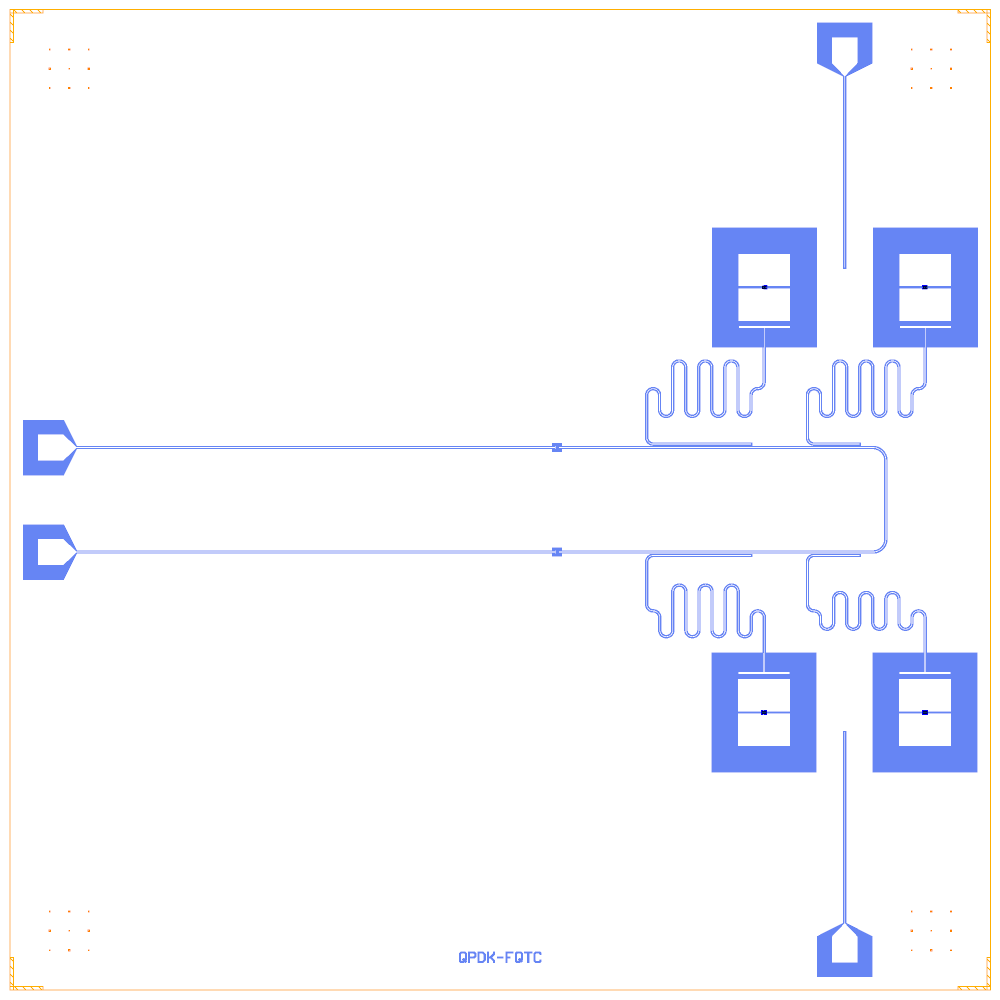

**On the chip so far:** 4 pads · 0 qubits · 6 other components · 9 routes · 0 declared couplings. **This step added** 10 component(s) `PAD_IN`, `PAD_OUT`, `PAD_FT`, `PAD_FB`, `C_IN`, `C_OUT`, `Q1`, `Q2` … (+2) and 9 route(s) `FL_IN`, `FL`, `FL_OUT`, `R1`, `R2`, `R3`, `R4`, `FLUX_T` … (+1).

junctions: {'Q1': 'Quantcore Squid', 'Q2': 'Quantcore Squid', 'Q3': 'Quantcore Squid', 'Q4': 'Quantcore Squid'}


In [5]:
d = Designer.load(OUT / "qubit_test_chip.json", out=Path("build/filled_qubit_test_chip.oas"), live=False)
d.path = None                                    # do not write back to qubit_test_chip.json
d.live = LIVE
d.data["name"] = "filled_qubit_test_chip"
d.data["chip"]["params"].update(
    name_chip="QPDK-FQTC",                       # device ID on the Quantcore die frame
    cheese="original",                           # no PDK band; the original's fill is set in Design 8
)
layout_step(d, STEPS / "s1_loaded.png", size=(1000, 1000), width=400)
print("junctions:", {n: s["params"].get("junction_type") for n, s in d.data["instances"].items() if n.startswith("Q")})

## Design 2 · View: the four launchers and the pad rule

**Pads:** the four launchers of the qubit test chip, placed with `edge="auto"` there, so their outer etch is
100 µm (`frame.pad_edge`) from the die edge. The picture zooms on the probeline input launcher `PAD_IN` at the west die edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PAD_IN | `BondPad` | w | 100.0 | ✓ |
| PAD_OUT | `BondPad` | w | 100.0 | ✓ |
| PAD_FT | `BondPad` | n | 100.0 | ✓ |
| PAD_FB | `BondPad` | s | 100.0 | ✓ |

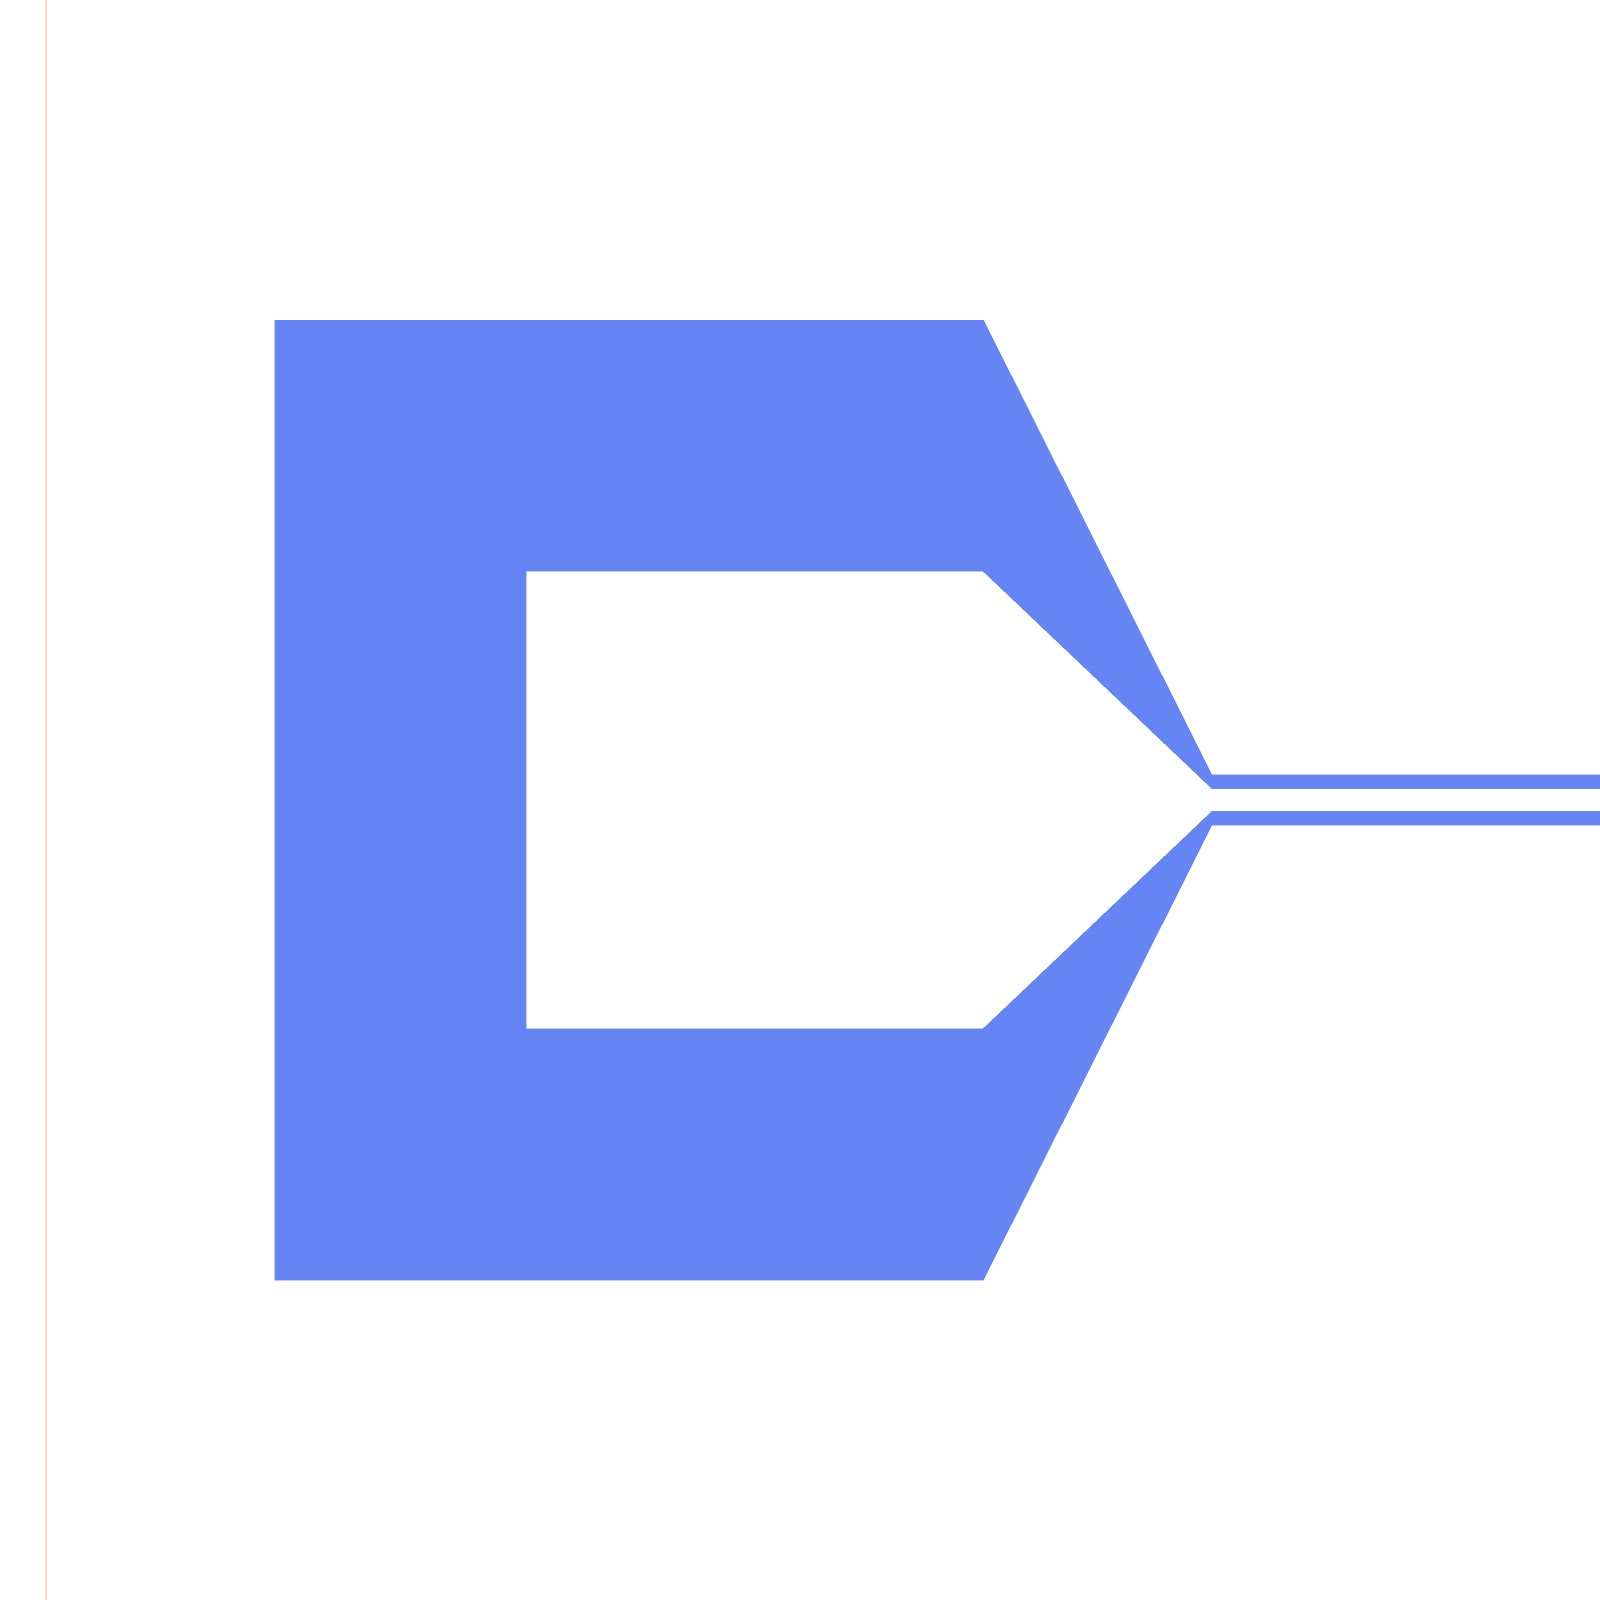

In [6]:
display(Markdown(pads_md(d)))
x0, y0, _, _ = d.design.chip.box
_, py = port_xy(d, "PAD_IN.a")
snap(d, STEPS / "s2_pads.png", box=(x0 - 20, py - 300, x0 + 680, py + 300), width=420);

## Design 3 · View: the probeline and its two IDCs

The readout line of the qubit test chip: the series IDCs `C_IN` / `C_OUT` (QPDK `interdigital_capacitor` defaults)
and the U-shaped probeline `FL` between them; the leads `FL_IN` / `FL_OUT` run on to the launchers at the west edge.

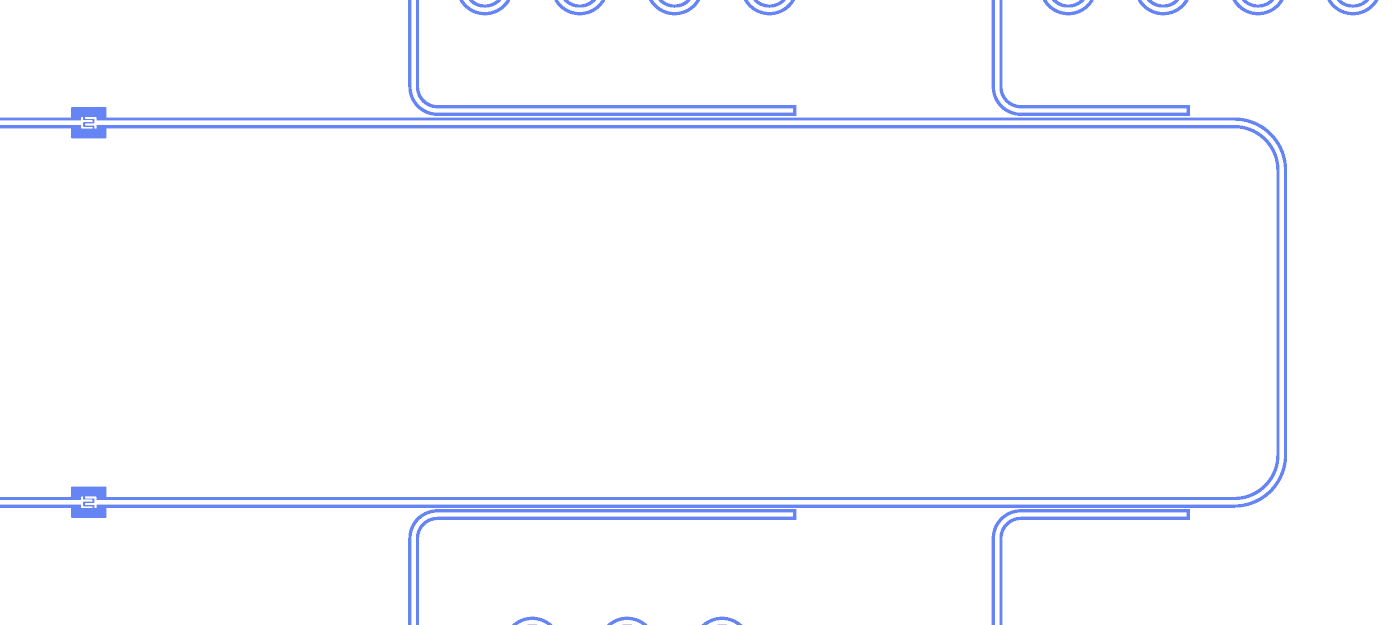

In [7]:
(xi, yi), (xo, yo) = port_xy(d, "C_IN.a"), port_xy(d, "C_OUT.a")
xu = max(x for x, _ in d.data["routes"]["FL"]["nodes"])          # the probeline's U-turn
snap(d, STEPS / "s3_probeline.png", box=(xi - 150, yo - 250, xu + 250, yi + 250), size=(1400, 625), width=560);

## Design 4 · View: the double-pad transmons

Q1 and Q2 above the probeline (QPDK `double_pad_transmon_with_bbox` as KQC `DoublePads`, coupler plate facing the
probeline), each with its trilayer SQUID in the 15 µm gap between the pads; Q3 / Q4 are their mirror images below.

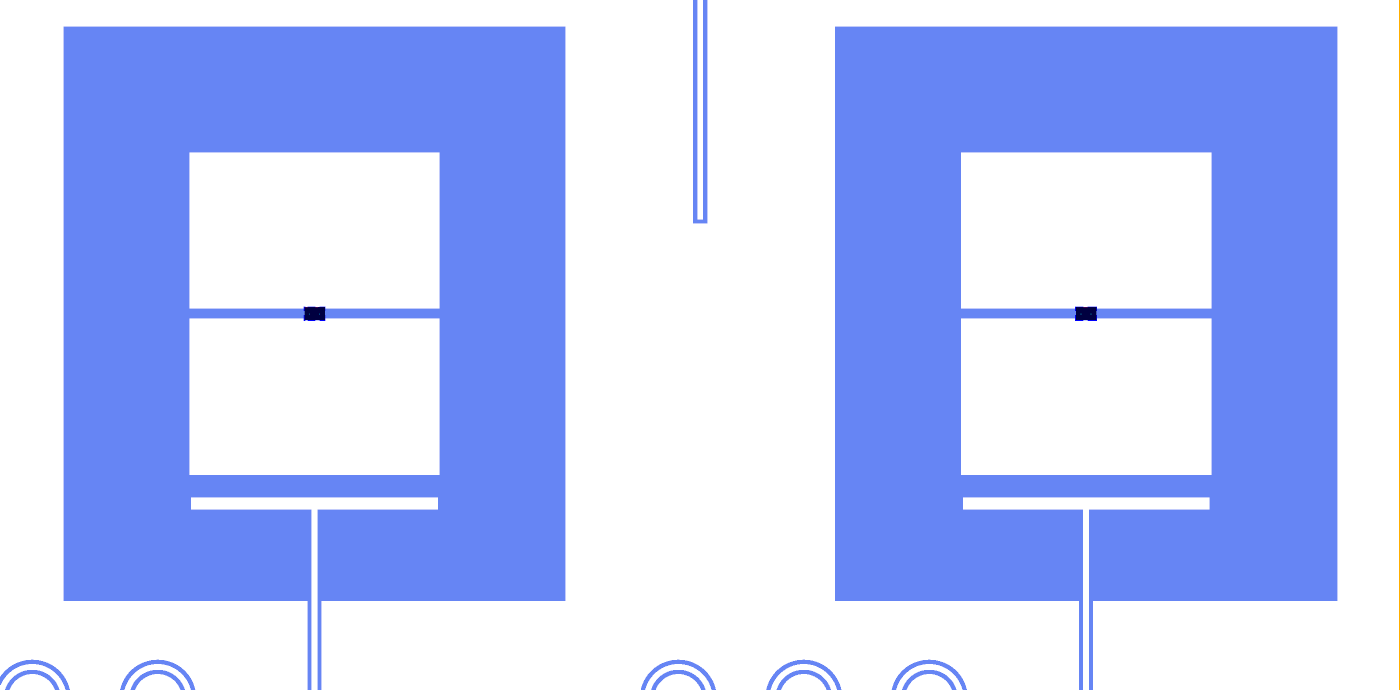

In [8]:
(x1, y1), (x2, _) = d.data["instances"]["Q1"]["place"]["at"], d.data["instances"]["Q2"]["place"]["at"]
snap(d, STEPS / "s4_qubits.png", box=(x1 - 500, y1 - 600, x2 + 500, y1 + 500), size=(1400, 690), width=560);

## Design 5 · View: the λ/2 readouts on the probeline

R1 and R2 between Q1 / Q2 and the probeline: each runs from its qubit's coupler plate, meanders, and ends in an open
coupled section hanging on the probeline (QPDK's 16 µm line-to-line gap). R3 / R4 hang below it the same way.

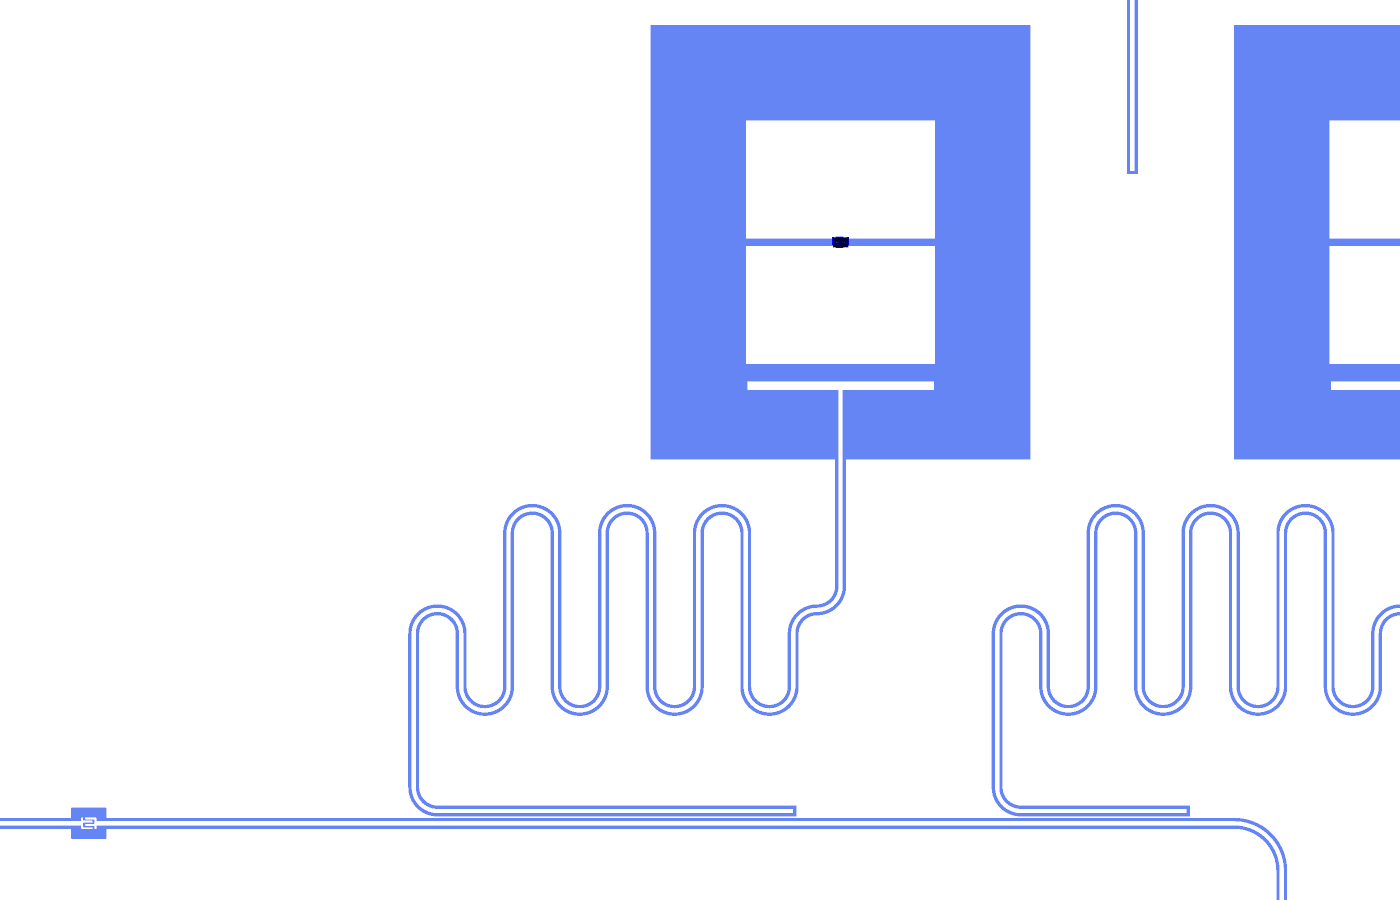

In [9]:
snap(d, STEPS / "s5_readouts.png", box=(xi - 150, yi - 150, xu + 250, y1 + 500), size=(1400, 900), width=560);

## Design 6 · Coupling: none on this chip

As on the qubit test chip, the qubits do not couple to each other; each talks only to its readout.

## Design 7 · View: the flux lines, and every route length

The top flux line's open end between Q1 and Q2 (the bottom one mirrors it), and the lengths of all nine routes, the
qubit test chip's.

{'FL_IN': 3638.5, 'FL': 5671.2, 'FL_OUT': 3638.5, 'R1': 5000.0, 'R2': 4600.0, 'R3': 3600.0, 'R4': 4800.0, 'FLUX_T': 1465.0, 'FLUX_B': 1465.0}


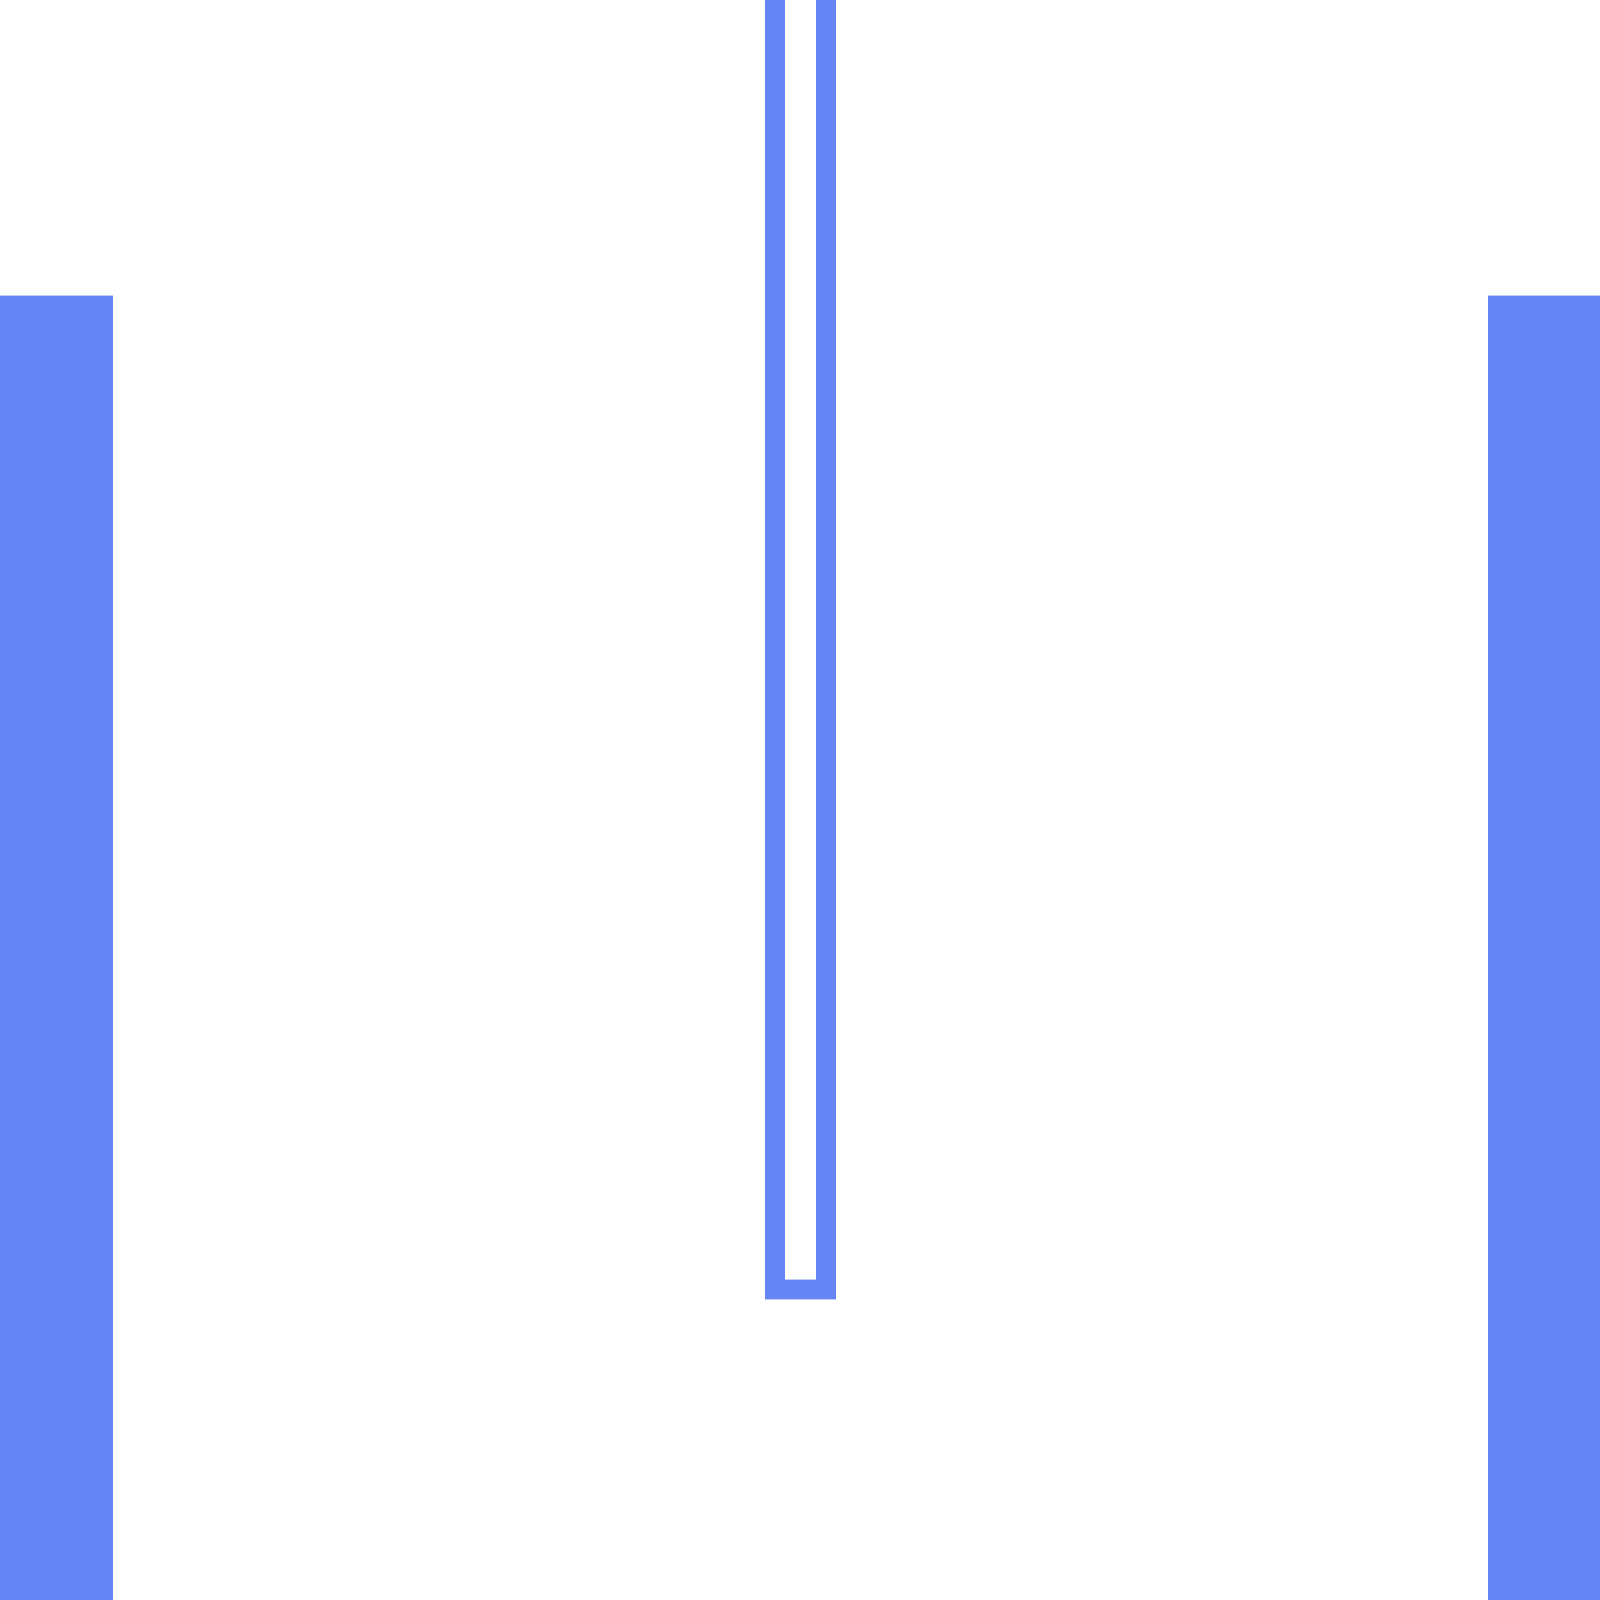

In [10]:
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
fx, fy = d.data["routes"]["FLUX_T"]["to"]["at"]                 # the free end of the top flux line
snap(d, STEPS / "s7_flux.png", box=(fx - 200, fy - 100, fx + 200, fy + 400), width=360);

## Design 8 · The fill, the sim groups, save

`QP.vortex_fill(d)` is QPDK's `fill_magnetic_vortices(rectangle_size=(15, 15), gap=70, stagger=2)` as a PDK
`CheeseRule` (built with `original_cheese(15, 85, clearance=70, d)`: 80 µm minus the PDK route margin, 10 µm).
Its fields go on the chip as the `cheese` rule dict, with `rows` 1000 so that it fills all the free ground, and the
chip is rebuilt: the fill is now part of the build. The sim groups come with the loaded design (one per qubit
with its readout and the probeline). Then the design is saved with `save_design`: it compares the file
with the one it replaces (the previous run's) and should say *same design*.

The picture is the filled chip; the fill is not a component, so the line below it adds nothing new.

CheeseRule(size=15.0, gap=70.0, rows=89, clearance=70.0, layer='M1')


**Same design as before:** `examples/designs/qpdk/filled_qubit_test_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer filled_qubit_test_chip: 10 instances, 9 routes, live=False> → examples\designs\qpdk\filled_qubit_test_chip.json | sim groups: ['Q1R1', 'Q2R2', 'Q3R3', 'Q4R4']


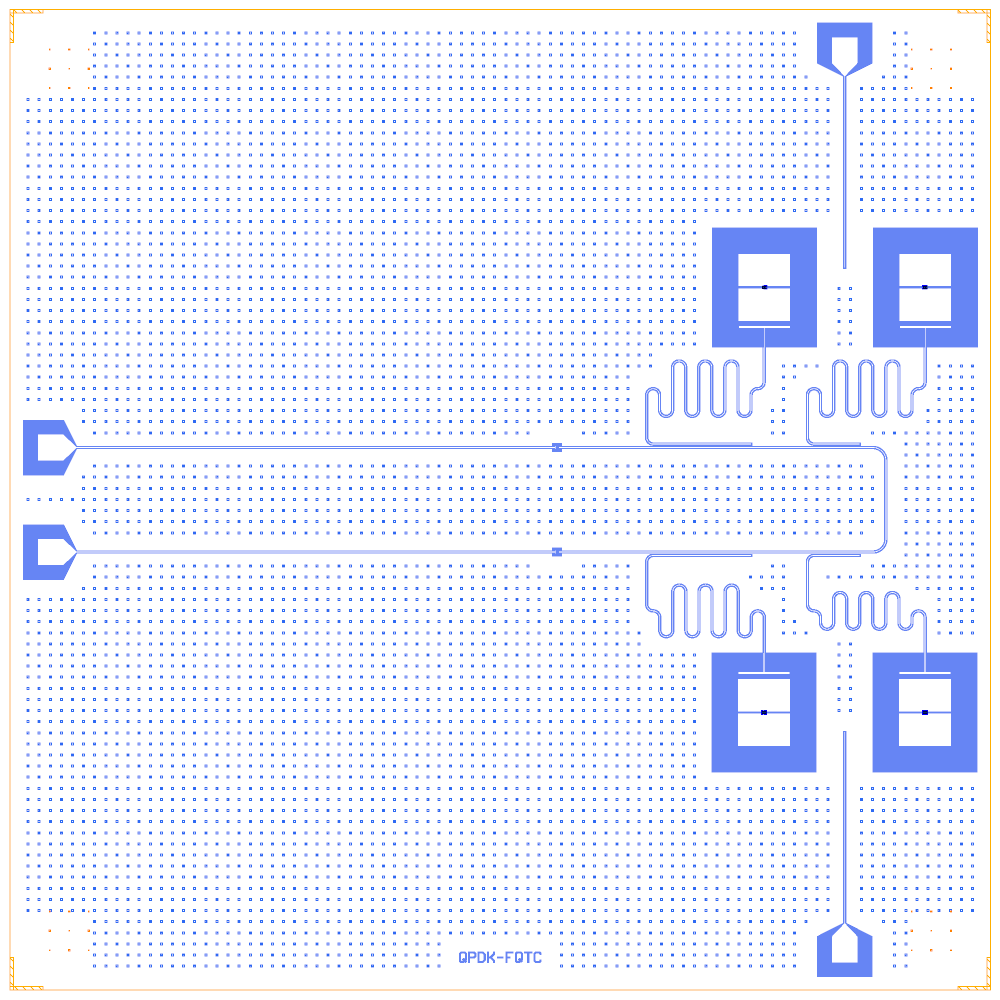

**On the chip so far:** 4 pads · 0 qubits · 6 other components · 9 routes · 0 declared couplings. **This step added** nothing new to the layout. The fill is drawn into the ground-grid layer.

WindowsPath('build/snapshots/filled_qubit_test_chip/s8_filled.png')

In [11]:
FILL = QP.vortex_fill(d)                         # QPDK's vortex fill as a PDK CheeseRule
d.data["chip"]["params"]["cheese"] = {"size": FILL.size, "gap": FILL.gap, "rows": 1000, "clearance": FILL.clearance}
print(FILL)
d.show()                                         # rebuild: the build now draws the fill (d.data was changed directly)
DESIGN, same = save_design(d, OUT / "filled_qubit_test_chip.json")
display(Markdown(same))
print(d, "→", DESIGN, "| sim groups:", sorted(d.data["sim_groups"]))
layout_step(d, STEPS / "s8_filled.png", size=(1000, 1000), width=400, note="The fill is drawn into the ground-grid layer.")

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced — the rebuild keeps the source's choices. `pdk_report` adds the
cheese source, the centring (of everything, pads included: (+0, +0) µm, as the qubit test chip) and the junction types.
Expected here (from the v1 run), as for the qubit test chip: four `dangling_port` warnings (the unused DoublePads `drive` ports) and no PDK
design warning. `pdk_report` reads "the original design's rule (drawn in the build): size 15, gap 70, rows 1000,
clearance 70" for the cheese.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit
nodes, routes join nodes (or become transmission-line resonators), pads are 50 Ω ports, flux / gate lines
are controls. The first table lists the nodes and the FEM nets that form each one, the second the
branches with their component estimates; the last one maps a few ports to their nodes.
The fill does not change the netlist (it lowers the ground-plane capacitance slightly; that needs FEM on the
filled geometry, and FEM exports never carry cheese).

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(('Q1.', 'R1',)))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Per qubit / readout pair with the probeline, exactly as the qubit test chip (same layout, same netlist). From the v1 run: f_q 5.763 GHz for all four, the readouts at 11.9–16.2 GHz.

In [ ]:
groups = {f"Q{i}R{i}": [f"Q{i}", f"R{i}", "FL"] for i in range(1, 5)}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each readout — the qubit
test chip's, since the fill does not enter the LOM.

In [ ]:
plot_lom(res, STEPS / "lom.png", title="filled_qubit_test_chip: LOM per qubit / readout pair")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The readout's coupling to the probeline is set by the coupled section's geometry: widen R1's ground strip to the
probeline from 4 to 10 µm (line-to-line gap 16 → 22 µm). The coupled-line κ drops steeply (the coupling falls
off fast with the gap), f_r and χ barely move. Done on a copy (`design_copy`), so the design keeps QPDK's 16 µm
gap.

In [ ]:
d2 = design_copy(DESIGN)
d2["R1"].set(to=dict(d2["R1"].spec["to"], ground_gap=10))
after = simulate_groups(d2, {"Q1R1": groups["Q1R1"]})
display(Markdown("**R1 ground strip to the probeline: 4 → 10 µm**\n\n" + params_delta_md({"Q1R1": res["Q1R1"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/qpdk/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The same four groups as the qubit test chip (Q3D C-matrix and eigenmode/EPR); the export builds without the fill.
Each sim group is cut out of the chip with its margin; every line leaving the box ends in a port, a
junction is a lumped port, and the cheese is never exported (simulation exports have none). The table
lists each job's ports and C-matrix nets (named after the islands, couplers and routes, so a result maps
back onto the LOM nodes). `FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

The geometry of these jobs is the qubit test chip's (no fill in simulation), but their design differs (name, chip parameters), so `fem_stage` loads only results solved for this design.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/qpdk/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed
unless `airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says
what the export left out (this chip has no airbridges, so both settings give the same geometry).

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group, `Q1R1` … `Q4R4`: the qubit's two pads, its coupler plate, the readout and
the probeline as named nets. Each net is named after its LOM node, so the matrix goes straight into the circuit
(Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same four boxes in HFSS eigenmode: the SQUID is a lumped L_J ‖ C_J sheet, every line the box cuts ends in 50 Ω,
so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the
junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box: S21 along the probeline, where R1's open coupled section
shows up as a notch. The library cannot hand the solved eigenmode **mesh** itself to a driven setup (no such option
yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the eigenmode job's mesh
seeds, the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and
a fast sweep around it. Q1R1 is the example; the other three groups go the same way.

In [ ]:
f_r1 = res["Q1R1"].params.get("R1.f_GHz")                 # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1R1", jobs_eig["Q1R1"][0], keep_eig["Q1R1"], f_guess=f_r1)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1R1"]:
    display(Markdown(driven_md(keep_drv["Q1R1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: a qubit; ≈ 0: a readout), with the LOM's frequencies of the same
components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {}
for i in range(1, 5):
    p = res[f"Q{i}R{i}"].params
    lom_f.update({f"Q{i}": p.get(f"Q{i}.f_q_GHz"), f"R{i}": p.get(f"R{i}.f_GHz")})
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own SQUID participates in most, the readout's
the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms,
κ = f/Q of the 50 Ω-terminated box. The driven run adds R1's S21 notch.

In [ ]:
fem_values = {}
for i in range(1, 5):
    keep = keep_eig.get(f"Q{i}R{i}")
    if keep:
        fem_values[f"Q{i}"] = epr_values(keep, {f"Q{i}": f"R{i}"}, {f"R{i}": lom_f[f"R{i}"]})
if keep_drv["Q1R1"]:
    fem_values.setdefault("Q1", {}).update({f"driven {k}": v for k, v in
                                            driven_values(keep_drv["Q1R1"], "R1", f_r1).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for vals in fem_values.values() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of each qubit and "
          "its readout from pyEPR, and the S21 notch of R1.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. Neither sees the fill (simulation exports
never carry cheese): its slightly lower ground-plane capacitance would need a filled FEM geometry.

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
for i in range(1, 5):
    g = f"Q{i}R{i}"
    est = res[g].params
    keys = [f"Q{i}.f_q_GHz", f"Q{i}.alpha_MHz", f"R{i}.f_GHz", f"R{i}.chi_MHz", f"R{i}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=groups[g]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    for key in keys:
        if key in fem_values.get(f"Q{i}", {}):
            rows.append((key, est.get(key), fem_values[f"Q{i}"][key], "eigenmode + pyEPR"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The same exercise target as the qubit test chip (the circuit is the same): **Q1 at 6.0 GHz**, ≈ 0.24 GHz above where
the LOM puts it (from the v1 run: 5.763 GHz). It is reachable inside the PDK junction window: the SQUID's L_J goes
from 6.73 nH to ≈ 6.2 nH, R_n ≈ 42 kΩ (`pdk_lj_bounds` keeps the feedback within 40–50 kΩ).

The targets go on a copy (`target_copy` → `build/filled_qubit_test_chip_target.json`), so the design file keeps its
own (none). `loop.analyse` runs the estimators on every qubit–readout pair — on the Q3D values where a solve was kept
(`Q3D_FILL`; `FILL` is the vortex rule of Design 8) — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J; to draw the new SQUID, size its fingers with `QP.trilayer_junction("DoublePads", lj_nH=..., squid=True)`. A
revision of this chip is a revision of the qubit test chip: carry an accepted change into that notebook, so the two
stay one design.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": 6.0}}               # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
Q3D_FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), Q3D_FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/filled_qubit_test_chip/revisions/`).
Without `RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's Q1R1 Q3D job (the
targeted pair) is exported and solved first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT
minutes). The table shows each iteration's value against the target and the knob it moved; the plot the residual in
tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q1R1 Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q1R1",)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, Q3D_FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `filled_qubit_test_chip.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/qpdk/filled_qubit_test_chip.json` rebuilds `build/filled_qubit_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the
filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers
2/0 + 4/0 and spacer 50/0 with the 51–53/0 dose gradient, flip-chip 800+/0 where used, and the frame
(100/0, 1000/0, 1001/0).
Here the cheese source is `build`: the build's own fill (15 µm holes, 85 µm pitch, 70 µm from 3/0) stands
(from the v1 run: 5667 holes on the mask) and no PDK band is added. The second table is a copy of the design with chip `cheese: "pdk"`, for comparison:
the PDK band (5 µm holes in 3 rows round the keep-outs, 4 µm from 3/0; 7735 holes in the v1 run) instead of the fill.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/filled_qubit_test_chip.json`
writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

In [ ]:
d3 = design_copy(DESIGN, "_pdkband")             # a copy of the design with the PDK band instead of the fill
d3.data["chip"]["params"]["cheese"] = "pdk"
display(Markdown("**For comparison, the PDK band instead of the fill:**\n\n"
                 + fab_layers_md(d3, path=Path("build") / "filled_qubit_test_chip_pdkband_fab.oas", cheese=True)))

## Fab 2 · Snapshots

The full die (compare QPDK's `filled_qubit_test_chip.png`, shown last, whose 100 µm etched edge the frame
replaces); the probeline input pad at the die edge; qubit Q1; the die frame's south-west corner; and the **fab
view** of Q1 and of an open ground area (the mask from Fab 1: 1/0 with QPDK's 15 µm vortex holes, 3/0, the
trilayer layers). The layout snapshots show the fill too (the build draws it into the ground-grid layer).

In [ ]:
show_snapshot(d, OUT / "filled_qubit_test_chip.png", size=(1500, 1500))
x0, y0, _, _ = d.design.chip.box
_, py = port_xy(d, "PAD_IN.a")
show_snapshot(d, OUT / "filled_qubit_test_chip_edge.png", box=(x0 - 20, py - 300, x0 + 680, py + 300), width=420)
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / "filled_qubit_test_chip_q1.png", box=(qx - 500, qy - 600, qx + 500, qy + 500), size=(1000, 1100), width=420)
show_snapshot(d, OUT / "filled_qubit_test_chip_frame.png", box=(-1625, -650, -725, 250), size=(900, 900), width=300)
snap_file(Path("build") / "filled_qubit_test_chip_fab.oas", OUT / "filled_qubit_test_chip_fab_q1.png",
          box=(qx - 700, qy - 800, qx + 700, qy + 700), size=(1000, 1070), width=420);

**The original.** gdsfactory is not installed in this environment, so the source is not rebuilt here; QPDK's own
render of the filled chip is shown from the local clone when present.

In [ ]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "filled_qubit_test_chip.png"   # QPDK's own render (MIT), from the local clone if present
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/filled_qubit_test_chip.png")

## Summary

| | |
|---|---|
| **matches the source** | the whole qubit test chip (loaded unchanged); QPDK's vortex fill: 15 µm squares on an 85 µm pitch, 80 µm clear of the CPWs |
| **differs (PDK)** | everything the qubit test chip changes (7.5 mm die and frame, pads 100 µm from the edge, the whole layout centred, sapphire, trilayer SQUIDs); the frame instead of QPDK's etched chip edge; the fill covers the die inside the frame (QPDK: the layout's bounding box) |
| **not reproduced** | the 2 µm row stagger of the fill (a `CheeseRule` is a square grid); QPDK fills only the layout's bounding box, the rebuild the whole design area |
| **PDK design warnings** | none |
| layout | loaded from the qubit test chip, shown in its segments (views), then the fill as this chip's own step; the saved JSON is the v1 notebook's |
| feedback | the qubit test chip's exercise target on a copy (Q1 6.0 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); an accepted change belongs in the qubit test chip notebook |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells (no fill in simulation) |